In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import zscore

# load data

In [2]:
#mne setup
import openneuro
import os
import mne
from mne.datasets import sample
from mne_bids import (
    BIDSPath,
    find_matching_paths,
    get_entity_vals,
    make_report,
    print_dir_tree,
    read_raw_bids
)

In [3]:
dataset = "ds007169"
if not os.path.exists('ds007169'):
    for i in range(1,21):
        subject = f"00{i}"
        if len(subject)==4:
            subject=subject[1:]
        if subject in ['013', '017']: continue #bad ids
        
        # Create a BIDS root directory in the MNE dataset folder
        bids_root = sample.data_path(download=False).parent / dataset
        bids_root.mkdir(parents=True, exist_ok=True)
        openneuro.download(dataset=dataset, target_dir=bids_root, include=[f"sub-{subject}"])
    

Using default location ~/mne_data for sample...
Creating /home/brouser/mne_data
🌍 Preparing to download ds007169 …
📥 Checking 17 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds007169 (downloaded 17 files and 49.5 MB).
Using default location ~/mne_data for sample...
🌍 Preparing to download ds007169 …
📥 Checking 17 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds007169 (downloaded 11 files and 49.1 MB).
Using default location ~/mne_data for sample...
🌍 Preparing to download ds007169 …
📥 Checking 17 files, downloading as needed (5 concurrent downloads). 


Output()

... (27 outputs left out)

Output()

✅ Finished downloading ds007169 (downloaded 11 files and 54.3 MB).
Using default location ~/mne_data for sample...
🌍 Preparing to download ds007169 …
📥 Checking 17 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds007169 (downloaded 11 files and 53.3 MB).


In [3]:
def load_subject(subject,
                 session = None,
                task = "nback",
                suffix = "eeg", #has ecg built in
                bids_root='ds007169'):
    subject = f"00{i}"
    if len(subject)==4:subject=subject[1:]
    if subject in ['013', '017']: return None
    bids_path = BIDSPath(root=bids_root, session=session, datatype='eeg')
    bids_path = bids_path.update(subject=subject, task=task, suffix=suffix)
    raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
    return raw

def loadBids()->list:   
    data=[]
    for i in range(1,21):
        raw=load_subject(i)
        if raw is not None: data.append(raw)
    return data

In [21]:
def filter_raw(
    raw,
    eeg_band=(1.0, 40.0),
    ecg_band=(0.5, 40.0),
    line_freq=50.0,
    copy=True,
    verbose="WARNING",
):
    """Bandpass + notch filter EEG and ECG channels of an mne.io.Raw object.

    Parameters
    ----------
    raw : mne.io.BaseRaw
        Raw recording. Data is loaded into memory if it is not already.
    eeg_band, ecg_band : tuple of (l_freq, h_freq)
        Bandpass edges in Hz for EEG and ECG channels respectively.
    line_freq : float
        Mains frequency. 50 Hz for Europe.
    copy : bool
        If True, the input is left untouched and a filtered copy is returned.

    Returns
    -------
    raw : mne.io.BaseRaw
        Filtered data. Channels other than EEG/ECG are left unfiltered.
    """
    if copy:
        raw = raw.copy()
    raw.load_data()

    nyq = raw.info["sfreq"] / 2.0

    # Notch at the line frequency and its harmonics, below Nyquist only
    notch_freqs = [f for f in np.arange(line_freq, nyq, line_freq) if f < nyq]

    groups = {
        "eeg": (dict(eeg=True, ecg=False), eeg_band),
        "ecg": (dict(eeg=False, ecg=True), ecg_band),
    }

    for name, (pick_kwargs, (l_freq, h_freq)) in groups.items():
        picks = mne.pick_types(raw.info, exclude=[], **pick_kwargs)
        if len(picks) == 0:
            continue

        if len(notch_freqs):
            raw.notch_filter(freqs=notch_freqs, picks=picks, verbose=verbose)

        raw.filter(
            l_freq=l_freq,
            h_freq=min(h_freq, nyq - 1.0) if h_freq is not None else None,
            picks=picks,
            method="fir",
            phase="zero",
            fir_design="firwin",
            verbose=verbose,
        )

    return raw


# Usage:
# raw_filt = filter_raw(raw)
# raw_filt = filter_raw(raw, eeg_band=(0.1, 100.0), ecg_band=(0.5, 70.0))

In [22]:
# save_processed.py
freqs=np.arange(0.1,60,0.5)
n_cycles=freqs/2
for i in range(1,21):
    session=load_subject(i)
    if session is None: continue
    session._data*=1e-6 #scale to correct units
    session=filter_raw(session)
    
    raw=zscore(session.get_data(picks=['eeg','ecg']),axis=1)
    raw=torch.tensor(raw)
    
    tfr=session.compute_tfr(method='morlet',freqs=freqs,n_cycles=n_cycles,picks=['eeg','ecg'], verbose=False, decim=4).get_data(picks=['eeg','ecg']) #shape [channel, freq, time]
    tfr=np.log(tfr) #log transform to better capture high frequency content
    tfr=zscore(tfr,axis=1)
    tfr=torch.tensor(tfr)

#epoch around events we care about
    event,event_id=mne.events_from_annotations(session,verbose=False)
    keeps={'1-back':event_id['1-back'],
            '2-back':event_id['2-back'],
            '3-back':event_id['3-back'],
            '4-back':event_id['4-back']
            }
    
    event=event[:,[0,2]]
    event = event[np.isin(event[:, 1], list(keeps.values()))]
    event[:,1]-= 10001
    event=torch.tensor(event)

    torch.save(
                {'raw':raw,
                'tfr':tfr,
                'labels':event
                },
            f'data/processed_data_{i}.pt')

/tmp/ipykernel_29747/2890753464.py:11: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
/tmp/ipykernel_29747/2890753464.py:11: RuntimeWarning: Unable to map the following column(s) to MNE:
handedness: R
analysis_included: true
data_quality_overall: pass
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
/tmp/ipykernel_29747/2890753464.py:11: RuntimeWarning: Unable to map the following column(s) to MNE:
handedness: R
analysis_included: true
data_quality_overall: pass
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
/tmp/ipykernel_29747/2890753464.py:11: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = read_raw_bids(bids_path=bids_path, verbose=False,extra_params={'preload':True})
/tmp/ipykernel_29747/2890753464.py:11: RuntimeWarning: Unable to map t

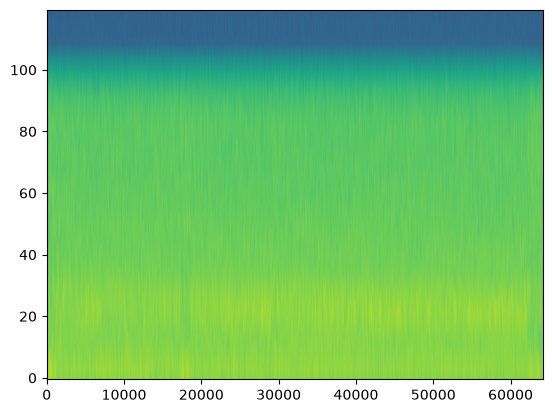

In [24]:
plt.figure()
plt.imshow(tfr[0],aspect='auto')
plt.gca().invert_yaxis()
plt.show()

# tensorboard + funcs

## old

In [ ]:
def elastic_net_loss(model, base_loss, l1_lambda=0, l2_lambda=0):
    l1_norm = base_loss.new_tensor(0.)
    l2_norm = base_loss.new_tensor(0.)
    for name, param in model.named_parameters():
        if not (param.requires_grad and 'weight' in name and 'bn' not in name.lower()):
            continue
        if l1_lambda:
            l1_norm += param.abs().sum()
        if l2_lambda:
            l2_norm += param.pow(2).sum()
    loss = base_loss
    if l1_lambda:
        loss = loss + l1_lambda * l1_norm
    if l2_lambda:
        loss = loss + l2_lambda * l2_norm
    return loss

In [ ]:
#launch tensorboard
from tensorboard import program
log_dir = "runs"
tb = program.TensorBoard()
tb.configure(argv=[None, '--logdir', log_dir])
tb_url = tb.launch()
print(f"TensorBoard is running at {tb_url}") #use ctrl+shift+p to find "simple browser"

In [ ]:
#depreciated
class EEGTransformerEncoderDecoder(nn.Module):
    """
    Transformer encoder/decoder for multi-channel EEG time series.

    Input:  (batch, C, N)   – C channels, N time steps per sample
    Output: (batch, C, N')  – C channels, N' output time steps (e.g. reconstruction or prediction)
    """

    def __init__(
        self,
        n_channels: int = 32,
        d_model: int = 128,
        nhead: int = 8,
        num_encoder_layers: int = 4,
        num_decoder_layers: int = 4,
        dim_feedforward: int = 256,
        dropout: float = 0.1,
        max_seq_len: int = 512,
        n_output_steps: int | None = None,  # if None, output length == input length
    ):
        super().__init__()
        self.spatial_attn = SpatialAttention(n_channels, d_k=16)
        self.local_conv = LocalTemporalConv(n_channels, kernel_size=5, stride=2)
        self.n_channels = n_channels
        self.d_model = d_model
        self.n_output_steps = n_output_steps or max_seq_len

        # Project C-channel signal at each time step into d_model
        self.input_proj = nn.Linear(n_channels, d_model)
        self.output_proj = nn.Linear(d_model, n_channels)

        # Learnable positional encodings
        self.encoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)
        self.decoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)

        # Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_encoder_layers)

        # Decoder
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_decoder_layers)

        # Masking
        self._build_causal_mask(max_seq_len)

    def _build_causal_mask(self, T: int):
        # Causal mask for decoder: position i can only attend to positions <= i
        self.register_buffer(
            "causal_mask",
            ~torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C, N = x.shape
        assert C == self.n_channels, f"Expected {self.n_channels} channels, got {C}"

        x = x.permute(0, 2, 1)
        x = self.spatial_attn(x)
        x = x.permute(0, 2, 1)
        x = self.local_conv(x)
        x = x.permute(0, 2, 1)

        x = self.input_proj(x)
        N_enc = x.size(1)
        x = x + self.encoder_pos[:, :N_enc, :]
        memory = self.encoder(x)            # ← remove the duplicate call

        N_out = self.n_output_steps
        tgt = torch.zeros(B, N_out, self.d_model, device=x.device, dtype=x.dtype)
        tgt = tgt + self.decoder_pos[:, :N_out, :]

        causal = self.causal_mask[:N_out, :N_out]
        # memory mask must be (N_out, N_enc), not (N, N_out)
        mem_mask = ~torch.triu(torch.ones(N_out, N_enc, dtype=torch.bool), diagonal=1)
        dec_out = self.decoder(
            tgt,
            memory,
            tgt_mask=causal,
            memory_mask=mem_mask,
        )

        out = self.output_proj(dec_out)
        out = out.permute(0, 2, 1)
        return out

In [ ]:
class LazyNeuroData(Dataset):
    def __init__(self, path='processed_data.pt', scale=1, transform=None,device='cpu'):
        processed=torch.load(path)
        self.data=processed['data'].to(device)
        self.labels=processed['labels'].to(device)
        self.num_samples = len(self.labels)
        self.scale = scale
        self.transform = transform

    def __len__(self): return self.num_samples
    
    def __getitem__(self, idx):
        data = self.data[idx]*self.scale #use transform here if required
        label = self.labels[idx]
        return data, label

## new

In [25]:
import os
import glob
import bisect
import itertools

import torch
from torch.utils.data import Dataset


class LazyNeuroData(Dataset):
    def __init__(self, paths='processed_data.pt', scale=1, transform=None,
                 device='cpu', lazy=True):
        self.paths = self._resolve_paths(paths)
        if not self.paths:
            raise FileNotFoundError(f'No .pt files found for {paths!r}')

        self.scale = scale
        self.transform = transform
        self.device = device
        self.lazy = lazy

        if lazy:
            # mmap=True: tensors are paged in from disk on access, not loaded up front
            self._shards = [torch.load(p, mmap=True) for p in self.paths]
            lengths = [len(s['labels']) for s in self._shards]
            self._cum = list(itertools.accumulate(lengths))  # running end index per file
            self.num_samples = self._cum[-1]
        else:
            shards = [torch.load(p) for p in self.paths]
            self.data = torch.cat([s['data'] for s in shards]).to(device)
            self.labels = torch.cat([s['labels'] for s in shards]).to(device)
            self.num_samples = len(self.labels)

    @staticmethod
    def _resolve_paths(paths):
        if isinstance(paths, (list, tuple)):
            return [str(p) for p in paths]
        paths = str(paths)
        if os.path.isdir(paths):
            return sorted(glob.glob(os.path.join(paths, '*.pt')))
        if any(c in paths for c in '*?['):
            return sorted(glob.glob(paths))
        return [paths]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        if idx < 0:
            idx += self.num_samples
        if not 0 <= idx < self.num_samples:
            raise IndexError(idx)

        if self.lazy:
            f = bisect.bisect_right(self._cum, idx)           # which file
            local = idx - (self._cum[f - 1] if f else 0)       # index within that file
            data = self._shards[f]['tfr'][local].to(self.device)
            label = self._shards[f]['labels'][local].to(self.device)
        else:
            data, label = self.data[idx], self.labels[idx]

        data = data * self.scale
        if self.transform is not None:
            data = self.transform(data)
        return data, label

In [ ]:
import os
import glob

import torch
from torch.utils.data import Dataset, DataLoader


class RandomWindowDataset(Dataset):
    """Random aligned (raw EEG window, TFR window) pairs from whole-recording .pt files.

    Each .pt file is a dict with (key names configurable):
        raw    : (C, T_raw)        raw EEG
        tfr    : (C, F, T_tfr)     time-frequency representation of the same recording
        events : (N, 2)            [sample_index, event_type]  (unused here)

    Parameters
    ----------
    paths : str | list[str]
        File, list of files, directory of .pt files, or glob pattern.
    win_len : int
        Target window length in RAW samples. Must be divisible by `decim`.
    context : int
        Extra raw samples fed on each side of the target window. The TFR value at the
        window edges depends on raw samples outside the window (wavelet length), so
        context lets the model see what the wavelets saw. Input length is
        win_len + 2 * context; the target covers only the central win_len samples.
    decim : int | None
        Raw samples per TFR time step (e.g. the `decim` used in MNE's tfr_morlet).
        None = infer from the files (round(T_raw / T_tfr)).
    windows_per_epoch : int
        Dataset length. Windows are drawn at random, so this just sets epoch size.
    seed : int | None
        None  -> fresh random windows every time (training).
        int   -> window `idx` is a fixed function of (seed, idx) (validation).
    """

    def __init__(self, paths, win_len=1024, context=0, decim=None,
                 windows_per_epoch=10_000, seed=None, transform=None,
                 raw_key='raw', tfr_key='tfr'):
        self.paths = self._resolve_paths(paths)
        if not self.paths:
            raise FileNotFoundError(f'No .pt files found for {paths!r}')

        self.win_len, self.context = win_len, context
        self.windows_per_epoch, self.seed = windows_per_epoch, seed
        self.transform = transform
        self.raw_key, self.tfr_key = raw_key, tfr_key

        # mmap: nothing is read into RAM until a window is sliced
        self._shards = [torch.load(p, mmap=True) for p in self.paths]

        # infer / check decimation factor
        ratios = {round(s[raw_key].shape[-1] / s[tfr_key].shape[-1]) for s in self._shards}
        if decim is None:
            if len(ratios) != 1:
                raise ValueError(f'Inconsistent raw/tfr length ratios across files: {ratios}')
            decim = ratios.pop()
        self.decim = decim
        if win_len % decim:
            raise ValueError(f'win_len ({win_len}) must be divisible by decim ({decim})')

        # number of valid (decim-aligned) start positions per file
        self._n_valid = []
        for p, s in zip(self.paths, self._shards):
            n_raw = s[raw_key].shape[-1]
            n_tfr = s[tfr_key].shape[-1]
            # start s0 = context + k*decim must satisfy:
            #   s0 + win_len + context <= n_raw   and   (s0 + win_len)//decim <= n_tfr
            last_start = min(n_raw - win_len - context, n_tfr * decim - win_len)
            n = (last_start - context) // decim + 1
            if n < 1:
                raise ValueError(f'{p} is too short for win_len={win_len}, context={context}')
            self._n_valid.append(n)

        # sample files proportionally to how many windows they contain
        w = torch.tensor(self._n_valid, dtype=torch.float)
        self._file_probs = w / w.sum()

    @staticmethod
    def _resolve_paths(paths):
        if isinstance(paths, (list, tuple)):
            return [str(p) for p in paths]
        paths = str(paths)
        if os.path.isdir(paths):
            return sorted(glob.glob(os.path.join(paths, '*.pt')))
        if any(c in paths for c in '*?['):
            return sorted(glob.glob(paths))
        return [paths]

    def __len__(self):
        return self.windows_per_epoch

    def __getitem__(self, idx):
        gen = None
        if self.seed is not None:
            gen = torch.Generator().manual_seed(self.seed + idx)

        f = torch.multinomial(self._file_probs, 1, generator=gen).item()
        k = torch.randint(0, self._n_valid[f], (1,), generator=gen).item()

        start = self.context + k * self.decim            # target start, raw samples
        shard = self._shards[f]

        raw = shard[self.raw_key][..., start - self.context:
                                  start + self.win_len + self.context]
        t0 = start // self.decim
        tfr = shard[self.tfr_key][..., t0: t0 + self.win_len // self.decim]

        raw, tfr = raw.float().clone(), tfr.clone()      # clone: detach from the mmap
        if self.transform is not None:
            raw, tfr = self.transform(raw, tfr)
        return raw, tfr


if __name__ == '__main__':
    train = RandomWindowDataset('processed/train/', win_len=1024, context=256)
    val = RandomWindowDataset('processed/val/', win_len=1024, context=256,
                              windows_per_epoch=2000, seed=0)

    train_dl = DataLoader(train, batch_size=64, num_workers=4, shuffle=False)
    val_dl = DataLoader(val, batch_size=64, num_workers=2, shuffle=False)

    raw, tfr = next(iter(train_dl))
    print(raw.shape, tfr.shape)  # (64, C, 1024 + 2*256), (64, C, F, 1024 // decim)

In [28]:
datafiles=os.listdir('data')
datafiles=['data/'+_d for _d in datafiles]
dataset=LazyNeuroData(datafiles)

In [29]:
d,l=dataset[0]

In [2]:
class SpatialAttention(nn.Module):
    """Channel-mixing via learned attention over C electrodes at each time step."""
    def __init__(self, n_channels: int, d_k: int = 16, dropout: float = 0.1):
        super().__init__()
        self.q = nn.Linear(n_channels, d_k)
        self.k = nn.Linear(n_channels, d_k)
        self.v = nn.Linear(n_channels, n_channels)
        self.attn_drop = nn.Dropout(dropout)
        self.scale = d_k ** -0.5

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, N, C)
        q = self.q(x)#.permute(0, 2, 1)   # (B, C, N)
        k = self.k(x).permute(0,2,1)                    # (B, N, C)
        attn = torch.bmm(q, k) * self.scale  # (B, C, C)
        attn = F.softmax(attn, dim=-1)
        attn = self.attn_drop(attn)
        out = torch.bmm(attn.permute(0, 2, 1), x)
        return out

class LocalTemporalConv(nn.Module):
    """Short 1-D conv to extract local temporal patterns and shorten sequence."""
    def __init__(self, n_channels: int, kernel_size: int = 5, stride: int = 2):
        super().__init__()
        pad = (kernel_size - 1) // 2
        self.conv = nn.Conv1d(n_channels, n_channels, kernel_size, stride=stride, padding=pad)
        self.norm = nn.LayerNorm(n_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, C, N)
        x = self.conv(x)
        x = self.norm(x.transpose(1, 2)).transpose(1, 2)
        return x

In [3]:
class EEGEncoder(nn.Module):
    """Extracts a latent representation from the EEG signal."""
    def __init__(
        self,
        n_channels: int = 32,
        d_model: int = 128,
        nhead: int = 8,
        num_encoder_layers: int = 4,
        dim_feedforward: int = 256,
        dropout: float = 0.1,
        max_seq_len: int = 512,
    ):
        super().__init__()
        self.spatial_attn = SpatialAttention(n_channels, d_k=16)
        self.local_conv = LocalTemporalConv(n_channels, kernel_size=5, stride=2)
        
        self.input_proj = nn.Linear(n_channels, d_model)
        
        # Learnable positional encodings
        self.encoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_encoder_layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, C, N)
        B, C, N = x.shape
        
        # Pre-processing
        x = x.permute(0, 2, 1)           # (B, N, C)
        x = self.spatial_attn(x)        # (B, N, C)
        x = x.permute(0, 2, 1)           # (B, C, N)
        x = self.local_conv(x)          # (B, C, N')
        x = x.permute(0, 2, 1)           # (B, N', C)

        # Projection and Encoding
        x = self.input_proj(x)          # (B, N', d_model)
        x = x + self.encoder_pos[:, :x.size(1), :]
        
        latent = self.transformer_encoder(x)
        return latent  # This is your latent representation

class EEGDecoder(nn.Module):
    """Reconstructs the original signal from the latent representation."""
    def __init__(
        self,
        n_channels: int = 32,
        d_model: int = 128,
        nhead: int = 8,
        num_decoder_layers: int = 4,
        dim_feedforward: int = 256,
        dropout: float = 0.1,
        max_seq_len: int = 512,
        n_output_steps: int = None,
    ):
        super().__init__()
        self.n_output_steps = n_output_steps or max_seq_len
        
        self.decoder_pos = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)
        
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.transformer_decoder = nn.TransformerDecoder(decoder_layer, num_decoder_layers)
        self.output_proj = nn.Linear(d_model, n_channels)
        
        # Causal mask
        self.register_buffer(
            "causal_mask",
            ~torch.triu(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool), diagonal=1),
        )

    def forward(self, memory: torch.Tensor, tgt_len: int) -> torch.Tensor:
        B, N_enc, D = memory.shape
        
        # Create a dummy target sequence (or use a shifted version of the input)
        # For a pure autoencoder, we often use a zero-initialized or shifted sequence
        tgt = torch.zeros(B, tgt_len, memory.size(-1), device=memory.device, dtype=memory.dtype)
        tgt = tgt + self.decoder_pos[:, :tgt_len, :]

        causal = self.causal_mask[:tgt_len, :tgt_len]
        mem_mask = ~torch.triu(torch.ones(tgt_len, N_enc, dtype=torch.bool, device=memory.device,), diagonal=1)
        
        dec_out = self.transformer_decoder(
            tgt,
            memory,
            tgt_mask=causal,
            memory_mask=mem_mask,
        )
        
        out = self.output_proj(dec_out)
        return out.permute(0, 2, 1) # (B, C, N)

class EEGAutoencoder(nn.Module):
    """Combined model for training."""
    def __init__(self, **kwargs):
        super().__init__()
        self.encoder = EEGEncoder(**kwargs)
        self.decoder = EEGDecoder(**kwargs)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        latent = self.encoder(x)
        # The decoder attempts to reconstruct the shape of the input
        # Note: You may need to adjust logic if the local_conv changes N
        reconstruction = self.decoder(latent, x.shape[2])
        return reconstruction

In [12]:
nsamples=100
nchannels=32
nfeatures=256

x=torch.randint(low=nfeatures*3,
                high=nfeatures*10,
                size=[nsamples])

frequencies = torch.randint(1,100,size=[nsamples]) #[f for f in range(1, 6)] # or any other logic to match len(x)

# Use zip to iterate over both lengths and frequencies
signals = [
    torch.stack([
        torch.sin(torch.linspace(0, 2 * torch.pi * f, steps=L))
        + torch.randn(L)
        for ch in range(nchannels)
    ])
    for L, f in zip(x, frequencies)
]
signals = nn.utils.rnn.pad_sequence(
    [s.T for s in signals],
    batch_first=True
).permute(0,2,1)
dataset=torch.utils.data.TensorDataset(signals,frequencies)
dataloader=DataLoader(dataset, batch_size=10,shuffle=True)

In [17]:
# Set seed for reproducibility
torch.manual_seed(42)

# Parameters (matching your existing setup)
nsamples = 100
nchannels = 32
nfeatures = 256  # This determines the sequence length L

# 1. Generate variable lengths L and a set of "signature" frequencies
# Each sample will have 3 primary frequencies that define its "identity"
x = torch.randint(low=nfeatures*3, high=nfeatures*10, size=[nsamples])
# Each sample gets 3 unique base frequencies
base_freqs = torch.randint(low=1, high=100, size=[nsamples, 3])

# 2. Generate the signals
signals = []
for i in range(nsamples):
    L = x[i].item()
    # Get the 3 base frequencies for this sample
    freqs = base_freqs[i]
    
    # Create a mixture of 3 sine waves with random phases and amplitudes
    # This ensures the model has to learn to reconstruct a specific "harmonic profile"
    sample_signal = torch.zeros((nchannels, L))
    for ch in range(nchannels):
        # Each channel has a slightly different phase to simulate real-world variance
        phase = torch.rand(1) * 2 * torch.pi
        
        # Sum of 3 sines
        sig = (
            1.0 * torch.sin(2 * torch.pi * freqs[0] * torch.arange(L) / L + phase) +
            0.7 * torch.sin(2 * torch.pi * freqs[1] * torch.arange(L) / L + phase) +
            0.4 * torch.sin(2 * torch.pi * freqs[2] * torch.arange(L) / L + phase)
        )
        # Add some Gaussian noise
        sig += torch.randn(L) * 0.1 
        sample_signal[ch] = sig
    
    signals.append(sample_signal)

# 3. Pad and format for the model
# We use the same logic as your original code to ensure compatibility
signals = nn.utils.rnn.pad_sequence(
    [s.T for s in signals],
    batch_first=True
).permute(0, 2, 1)

# The frequencies are used as a "ground truth" for validation of the signal profile
dataset = TensorDataset(signals, base_freqs)
dataloader = DataLoader(dataset, batch_size=10, shuffle=True)

print(f"Dataset created. Shape: {signals.shape}") # Should be [100, 32, nfeatures*10]

Dataset created. Shape: torch.Size([100, 32, 2532])


In [19]:
#autoencoder training
device='cuda' if torch.cuda.is_available() else 'cpu'
autoencoder = EEGAutoencoder(n_channels=32, d_model=128,max_seq_len=signals.shape[-1]).to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-4)
schedular=torch.optim.lr_scheduler.StepLR(optimizer, gamma=0.1,step_size=100)

# Training loop
losses=[]
lr=[]
autoencoder.train()
for epoch in range(100):
    for batch in dataloader:
        x=batch[0].to(device)
        y=batch[1].to(device)
        optimizer.zero_grad()
        output = autoencoder(x)
        loss = F.mse_loss(output, x)
        loss.backward()
        optimizer.step()
        losses.append(loss.cpu().item())

        schedular.step()
        lr.append(schedular.get_last_lr())

plt.figure()
plt.plot(losses)
plt.show()

autoencoder.eval()
#with torch.no_grad():
x_pred=autoencoder(x)
plt.figure()
plt.plot(x[0,0].cpu())
plt.plot(x_pred[0,0].detach().cpu(),linestyle='--',color='red')
plt.show()

# Load only the encoder
#encoder = EEGEncoder(n_channels=32, d_model=128)
#encoder.load_state_dict(torch.load('encoder_weights.pt'))
#encoder.eval()

#with torch.no_grad():
#    latent_representation = encoder(input_data)
    # Proceed with predictions using latent_representation

[W1031 00:46:11.367300632 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 257949696 bytes (free: 5242880, total: 3951624192).
[W1031 00:46:13.900649112 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 257949696 bytes (free: 156237824, total: 3951624192).
[W1031 00:46:13.900729763 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 257949696 bytes (free: 156237824, total: 3951624192).


OutOfMemoryError: CUDA out of memory. Tried to allocate 246.00 MiB. GPU 0 has a total capacity of 3.68 GiB of which 149.00 MiB is free. Including non-PyTorch memory, this process has 3.52 GiB memory in use. Of the allocated memory 2.29 GiB is allocated by PyTorch, and 1.11 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [11]:

print(f"Parameters: {sum(p.numel() for p in autoencoder.parameters()):,}")


Parameters: 1,993,792


In [5]:
# ── Instantiate model ──
model = EEGTransformerEncoderDecoder(
    n_channels=32,
    d_model=128,
    nhead=8,
    num_encoder_layers=4,
    num_decoder_layers=4,
    dim_feedforward=256,
    dropout=0.1,
    max_seq_len=512,
    n_output_steps=128,       # predict next 128 steps
)
model.eval()
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


Parameters: 1,471,808


In [6]:
# ── Test 1: basic forward pass ──
x = torch.randn(4, 32, 256)   # batch=4, C=32, N=256
with torch.no_grad():
    y = model(x)
print(f"\nTest 1 – forward pass")
print(f"  Input:  {tuple(x.shape)}")
print(f"  Output: {tuple(y.shape)}")
assert y.shape[0] == 4 and y.shape[1] == 32, "Shape mismatch!"

RuntimeError: Expected size for first two dimensions of batch2 tensor to be: [4, 16] but got: [4, 256].

In [ ]:
# ── Test 2: different sequence lengths ──
for N in [64, 128, 512]:
    x = torch.randn(2, 32, N)
    with torch.no_grad():
        y = model(x)
    print(f"Test 2 – N={N:3d}  →  output {tuple(y.shape)}")


In [ ]:
# ── Test 3: single sample ──
x1 = torch.randn(1, 32, 256)
with torch.no_grad():
    y1 = model(x1)
print(f"Test 3 – batch=1  →  output {tuple(y1.shape)}")


In [ ]:
# ── Test 4: gradient flow (training step) ──
model.train()
x = torch.randn(4, 32, 256, requires_grad=False)
y = model(x)
loss = F.mse_loss(y, x[:, :, :y.shape[2]])   # reconstruct first N_out samples
loss.backward()

# Check that gradients exist for key params
grads_ok = all(
    p.grad is not None and torch.isfinite(p.grad).all()
    for p in model.parameters() if p.requires_grad
)
print(f"\nTest 4 – backward pass")
print(f"  Loss:     {loss.item():.6f}")
print(f"  Grads:    {'OK (finite, non-None)' if grads_ok else 'FAILED'}")

# ── Test 5: numerical stability (extreme inputs) ──
x_big  = torch.randn(2, 32, 128) * 10    # large amplitude
x_small = torch.randn(2, 32, 128) * 0.01 # near-zero
with torch.no_grad():
    y_big  = model(x_big)
    y_small = model(x_small)
print(f"\nTest 5 – numerical stability")
print(f"  x*10    → finite: {torch.isfinite(y_big).all().item()}")
print(f"  x*0.01  → finite: {torch.isfinite(y_small).all().item()}")

print("\n✓ All tests passed")

Parameters: 1,471,808


RuntimeError: Expected size for first two dimensions of batch2 tensor to be: [4, 16] but got: [4, 256].